# The Summary of all kinds of distrubution 

In [1]:
print(1)

1


k: [0 1]
probs: [0.8 0.2]


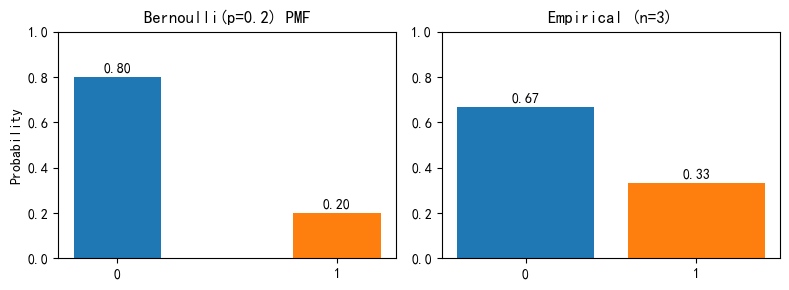

In [81]:
import numpy as np  # 导入 NumPy，用于数值计算
import matplotlib.pyplot as plt  # 导入 Matplotlib，用于绘图

def plot_bernoulli_pmf(p=0.3, ax=None):  # 定义函数：绘制伯努利分布的概率质量函数（PMF）
    k = np.array([0, 1])  # 定义伯努利随机变量的两个可能取值 0 和 1
    print('k:', k)  # 打印取值数组，便于调试查看
    probs = np.array([1 - p, p])  # 计算对应概率：P(X=0)=1-p，P(X=1)=p
    print('probs:', probs)  # 打印概率数组，便于调试查看
    created = False  # 标记是否在函数内部新建了坐标轴
    if ax is None:  # 如果没有传入坐标轴对象
        fig, ax = plt.subplots(figsize=(4,3))  # 创建新的图像和坐标轴
        created = True  # 记录当前坐标轴由本函数创建
        print('ax:', ax)  # 打印坐标轴对象，便于调试查看
    ax.bar(k, probs, width=0.4, color=['C0','C1'])  # 绘制 PMF 柱状图
    ax.set_xticks(k)  # 设置 x 轴刻度位置为 0 和 1
    ax.set_xticklabels(['0','1'])  # 设置 x 轴刻度标签文本
    ax.set_ylim(0, 1)  # 设置 y 轴范围为 0 到 1
    ax.set_ylabel('Probability')  # 设置 y 轴标题
    ax.set_title(f'Bernoulli(p={p}) PMF')  # 设置图标题并显示参数 p
    for xi, yi in zip(k, probs):  # 遍历每个柱子的横坐标和概率值
        ax.text(xi, yi + 0.02, f'{yi:.2f}', ha='center')  # 在柱子上方标注概率数值
    if created:  # 如果图像由当前函数创建
        plt.show()  # 显示图像

def plot_bernoulli_samples(p=0.3, n=1000, seed=0):  # 定义函数：采样并与理论分布对比
    np.random.seed(seed)  # 设置随机种子，保证结果可复现
    samples = np.random.binomial(1, p, size=n)  # 从伯努利分布采样 n 次
    counts = np.bincount(samples, minlength=2)  # 统计 0 和 1 出现次数
    probs_est = counts / n  # 计算经验概率（频率）

    fig, axs = plt.subplots(1, 2, figsize=(8,3))  # 创建 1 行 2 列子图
    plot_bernoulli_pmf(p, ax=axs[0])  # 在左侧子图绘制理论 PMF
    axs[1].bar([0,1], probs_est, color=['C0','C1'])  # 在右侧子图绘制经验概率柱状图
    axs[1].set_xticks([0,1])  # 设置右图 x 轴刻度为 0 和 1
    axs[1].set_ylim(0,1)  # 设置右图 y 轴范围为 0 到 1
    axs[1].set_title(f'Empirical (n={n})')  # 设置右图标题并显示样本量
    for xi, yi in enumerate(probs_est):  # 遍历经验概率的索引和值
        axs[1].text(xi, yi + 0.02, f'{yi:.2f}', ha='center')  # 在柱子上方标注经验概率
    plt.tight_layout()  # 自动调整子图间距，避免重叠
    plt.show()  # 显示图像

# 运行示例：用 p=0.2、样本量 5000、随机种子 42 进行演示
plot_bernoulli_samples(p=0.2, n=3, seed=42)  # 调用函数执行示例

In [ ]:
import numpy as np
from scipy.stats import bernoulli

# 创建一个伯努利分布对象，p是成功的概率
p = 0.3  # 例如，成功的概率是50%
dist = bernoulli(p)

# 生成伯努利分布的随机变量
random_vars = dist.rvs(20)  # 生成10个随机变量
print(random_vars)

# 计算特定值的概率质量函数（PMF）
print(dist.pmf(1))  # 计算成功的概率
print(dist.pmf(0))  # 计算失败的概率

# 计算累积分布函数（CDF）
print(dist.cdf(1))  # 计算成功之前的累积概率
print(dist.cdf(0))  # 计算失败之前的累积概率


import numpy as np

# 生成伯努利分布的随机变量，n=1表示试验次数为1，p是成功的概率
p = 0.1  # 例如，成功的概率是50%
random_vars = np.random.binomial(n=1, p=p, size=10)  # 生成10个随机变量
print(random_vars)



import numpy as np

p = 0.5  # 成功的概率

# 概率质量函数（PMF）
def pmf(k, p):
    # 伯努利分布的概率质量函数（PMF）。
    # 若 k 为 0 或 1，则按照公式计算：P(X=k) = p^k * (1-p)^(1-k)。
    # 说明：当 k==1 时，p**1 * (1-p)**0 = p；当 k==0 时，p**0 * (1-p)**1 = 1-p。
    # 对于其他取值（非 0/1），伯努利分布的概率为 0，所以返回 0。
    return p**k * (1-p)**(1-k) if k in [0, 1] else 0

# 计算特定值的概率质量函数（PMF）
print(pmf(1, p))  # 计算成功的概率
print(pmf(0, p))  # 计算失败的概率

# 累积分布函数（CDF）
def cdf(k, p):
    return sum(pmf(i, p) for i in range(k+1)) if k in [0, 1] else 0 if k < 0 else 1

# 计算累积分布函数（CDF）
print(cdf(1, p))  # 计算成功之前的累积概率
print(cdf(0, p))  # 计算失败之前的累积概率

[1 0 1 0 0 1 0 0 0 0 0 0 1 0 0 1 1 0 0 0]
0.3
0.7000000000000002
1.0
0.7
[0 0 0 0 0 1 1 0 0 0]
0.5
0.5
1.0
0.5


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import bernoulli

# 设置中文字体，防止图表中的中文显示为方块
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 可用黑体
# plt.rcParams['font.sans-serif'] = ['Arial Unicode MS'] # Mac 用户请使用此行
plt.rcParams['axes.unicode_minus']

True

f:\ProgramRepository\CondaEnv\MachineLearning\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


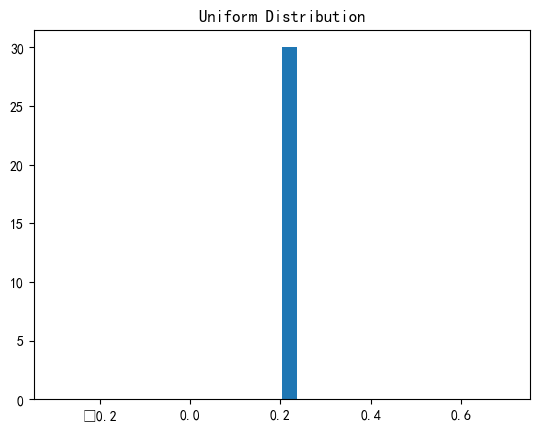

In [57]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import beta
from scipy.stats import weibull_min

def uniform_distribution(a, b, size=1000):
    return np.random.uniform(a, b, size)

a = 0
b = 10
size = 1
samples = uniform_distribution(a, b, size)
plt.hist(samples, bins=30, density=True)
plt.title("Uniform Distribution")
plt.show()